<a href="https://colab.research.google.com/github/IgorKlymenko/robot-joystick-from-foundation-model/blob/test-description/notebooks/experiments_Octo_Teleoperation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tests with running Octo


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

✨🍰✨ Everything looks OK!


In [ ]:
import condacolab
condacolab.check()

!conda create -n octo python=3.10 -y
print('Installing octo project in conda environment...')
!git clone https://github.com/IgorKlymenko/robot-joystick-from-foundation-model.git

✨🍰✨ Everything looks OK!
Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / done


==> WARNING: A newer version of conda exists. <==
    current version: 24.11.2
    latest version: 26.5.2

Please update conda by running

    $ conda update -n base -c conda-forge conda



## Package Plan ##

  environment location: /usr/local/envs/octo

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-4.5          |           20_gnu          28 KB  conda-forge
    bzip2-1.0.8                |       hda65f42_9         254 KB  conda-forge
    ca-certificates-2026.5.20  |       hbd8a1cb_0         127 KB  conda-forge
    ld_impl_linux-64-2.45.1    |default_hbd61a6d_102         711 KB  conda-forge
    libexpat-2.8.1             |       hecca717_0          75 KB  conda-forge
    libffi-3.5.2               |       h3435931_0        

In [ ]:
%cd robot-joystick-from-foundation-model
!conda run -n octo pip3 install -e .
!conda run -n octo pip3 install -r requirements.txt
!conda run -n octo pip3 install --upgrade "jax[cuda12_pip]==0.4.20" -f https://storage.googleapis.com/jax-releases/jax_cuda_releases.html
!conda run -n octo pip install scipy==1.11.4

/content/octo_teleoperation
Obtaining file:///content/octo_teleoperation
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for octo (pyproject.toml): started
  Building editable for octo (pyproject.toml): finished with status 'done'
  Created wheel for octo: filename=octo-0.0.0-0.editable-py3-none-any.whl size=3432 sha256=e94732b6c5fa384278595b1d447f07fe00946c8306fd8f2186caa00b24ffefb6
  Stored in directory: /tmp/pip-ephem-wheel-cache-xoh2w7hp/wheels/c9/f1/47/521e3e5b62aa6ba64ad5e6aea065a47479be88cc3932fa1a76
Successfully built 

In [ ]:
!conda run -n octo python -m pip install "numpy<2" --force-reinstall
!conda run -n octo python -c "import numpy as np; print(np.__version__, np.__file__)"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 95.7 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.24.3
    Uninstalling numpy-1.24.3:
      Successfully uninstalled numpy-1.24.3

1.26.4 /usr/local/envs/octo/lib/python3.10/site-packages/numpy/__init__.py



In [ ]:
print("=== Installing cuDNN 8.9 to match JAX requirements ===")
!conda run -n octo pip uninstall -y nvidia-cudnn-cu12
!conda run -n octo pip install nvidia-cudnn-cu12==8.9.4.25

print("\n=== Checking installed version ===")
!conda run -n octo pip show nvidia-cudnn-cu12

print("\n=== Testing GPU access ===")
result = !conda run -n octo python -c "import site; print(site.getsitepackages()[0])"
conda_site = result[0]
lib_path = f"{conda_site}/nvidia/cudnn/lib:{conda_site}/nvidia/cublas/lib:{conda_site}/nvidia/cuda_runtime/lib"

!conda run -n octo bash -c "export LD_LIBRARY_PATH={lib_path}:\$LD_LIBRARY_PATH && python -c 'import jax; print(\"Devices:\", jax.devices()); print(\"Backend:\", jax.default_backend())'"

=== Installing cuDNN 8.9 to match JAX requirements ===
Found existing installation: nvidia-cudnn-cu12 9.23.0.39
Uninstalling nvidia-cudnn-cu12-9.23.0.39:
  Successfully uninstalled nvidia-cudnn-cu12-9.23.0.39

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 720.1/720.1 MB 26.4 MB/s  0:00:17


=== Checking installed version ===
Name: nvidia-cudnn-cu12
Version: 8.9.4.25
Summary: cuDNN runtime libraries
Home-page: https://developer.nvidia.com/cuda-zone
Author: Nvidia CUDA Installer Team
Author-email: cuda_installer@nvidia.com
License: NVIDIA Proprietary Software
Location: /usr/local/envs/octo/lib/python3.10/site-packages
Requires: nvidia-cublas-cu12, nvidia-cuda-nvrtc-cu12
Required-by: 


=== Testing GPU access ===
Devices: [cuda(id=0)]
Backend: gpu



In [ ]:
## USE FOR THE CODE UPDATES TO FETCH BEFORE RUNNING THE CODE
%cd ..
%rm -rf robot-joystick-from-foundation-model
!git clone https://github.com/IgorKlymenko/robot-joystick-from-foundation-model.git
%cd robot-joystick-from-foundation-model

/content
Cloning into 'octo_teleoperation'...
remote: Enumerating objects: 6161, done.
remote: Total 6161 (delta 0), reused 0 (delta 0), pack-reused 6161 (from 1)
Receiving objects: 100% (6161/6161), 23.64 MiB | 39.23 MiB/s, done.
Resolving deltas: 100% (3904/3904), done.
/content/octo_teleoperation


In [ ]:
### TESTING THE ACTION HEAD
!conda run -n octo python scripts/smoke_test_teleop_head.py

✓ Action head initializes and runs forward pass
  Mean shape: (2, 1, 1, 7), Cov shape: (2, 1, 1, 7, 7)

2026-06-09 01:16:35.395575: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-09 01:16:35.395629: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-09 01:16:35.397040: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-09 01:16:36.255067: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT



In [ ]:
!conda run -n octo python -c "import jax; print('JAX devices:', jax.devices()); print('JAX device count:', jax.device_count()); print('JAX default backend:', jax.default_backend()); print('JAX local devices:', jax.local_devices()); print('✅ GPU is being used!' if jax.default_backend() == 'gpu' else '❌ GPU is NOT being used (using CPU or TPU)'); import jax.numpy as jnp; x = jnp.ones((100, 100)); result = jnp.dot(x, x); print(f'Computation device: {result.device()}')"

JAX devices: [cuda(id=0)]
JAX device count: 1
JAX default backend: gpu
JAX local devices: [cuda(id=0)]
✅ GPU is being used!
Computation device: cuda:0



In [ ]:
### DATASET
!wget -P data/ https://rail.eecs.berkeley.edu/datasets/example_sim_data.zip
!unzip data/example_sim_data.zip -d data/

--2026-06-09 01:16:44--  https://rail.eecs.berkeley.edu/datasets/example_sim_data.zip
Resolving rail.eecs.berkeley.edu (rail.eecs.berkeley.edu)... 128.32.244.190
Connecting to rail.eecs.berkeley.edu (rail.eecs.berkeley.edu)|128.32.244.190|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 419112468 (400M) [application/zip]
Saving to: ‘data/example_sim_data.zip’

example_sim_data.zi 100%[===================>] 399.70M  38.2MB/s    in 10s     

2026-06-09 01:16:55 (39.1 MB/s) - ‘data/example_sim_data.zip’ saved [419112468/419112468]

Archive:  data/example_sim_data.zip
   creating: data/aloha_sim_dataset/
   creating: data/aloha_sim_dataset/aloha_sim_cube_scripted_dataset/
   creating: data/aloha_sim_dataset/aloha_sim_cube_scripted_dataset/1.0.0/
  inflating: data/aloha_sim_dataset/aloha_sim_cube_scripted_dataset/1.0.0/aloha_sim_cube_scripted_dataset-train.tfrecord-00003-of-00008  
  inflating: data/aloha_sim_dataset/aloha_sim_cube_scripted_dataset/1.0.0/aloha_sim_c

In [ ]:
### Code to finetune 3 models over specific horixons
!conda run -n octo python scripts/multi_horizon_finetune.py \
    --pretrained_path=hf://rail-berkeley/octo-small-1.5 \
    --data_dir=data/aloha_sim_dataset \
    --base_save_dir=/content/models \
    --batch_size=32 \
    --action_horizons=15,5,1 \
    --num_steps=2000 \
    --freeze_transformer=false

2026-06-09 01:17:02.550037: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-09 01:17:02.550085: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-09 01:17:02.551291: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-09 01:17:03.392700: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
I0609 01:17:05.836452 132184057431872 xla_bridge.py:633] Unable to initialize backend 'rocm': NOT_FOUND: Could not find registered platform with name: "rocm". Available platform names are: CUDA
I0609 01:17:05.838287 132184057431872 xla_bridg

In [ ]:
%load_ext tensorboard
%tensorboard --logdir=/content/models

In [ ]:
!conda run -n octo python scripts/multi_horizon_predict.py \
    --base_model_dir=/content/models \
    --data_dir=data/aloha_sim_dataset \
    --training_horizons=1,5,15 \
    --prediction_horizons=1,5,15 \
    --num_trajectories=3 \
    --n_cov_samples=128 \
    --batch_size=64 \
    --output_dir=/content/experiments

2026-06-09 01:17:22.032349: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-09 01:17:22.032398: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-09 01:17:22.033658: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-09 01:17:22.918353: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
W0609 01:17:25.309818 138463847704384 compilation_cache.py:59] Initialized persistent compilation cache at /root/.jax_compilation_cache
I0609 01:17:25.310663 138463847704384 multi_horizon_predict.py:489] Training horizons: [1, 5, 15]
I0609 0

/tmp/ipykernel_776/1871904381.py:29: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(
/tmp/ipykernel_776/1871904381.py:29: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(
/tmp/ipykernel_776/1871904381.py:29: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(
/tmp/ipykernel_776/1871904381.py:29: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(


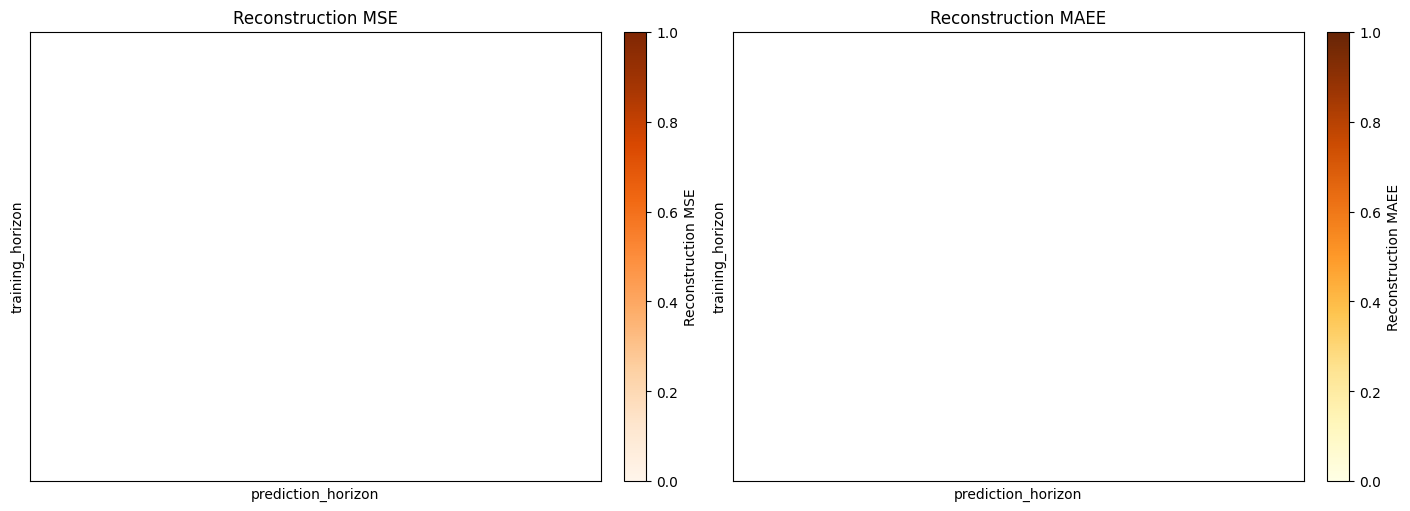

In [ ]:
# Colab cell: Reconstruction MSE / MAE heatmaps (orange tones)

import json
import numpy as np
import matplotlib.pyplot as plt

# ---- load data ----
path = "/content/experiments/summary.json"
with open(path, "r") as f:
    rows = json.load(f)

train_vals = sorted({r["training_horizon"] for r in rows})
pred_vals  = sorted({r["prediction_horizon"] for r in rows})

train_idx = {v: i for i, v in enumerate(train_vals)}
pred_idx  = {v: j for j, v in enumerate(pred_vals)}

recon_mse = np.full((len(train_vals), len(pred_vals)), np.nan)
recon_mae = np.full((len(train_vals), len(pred_vals)), np.nan)

for r in rows:
    i = train_idx[r["training_horizon"]]
    j = pred_idx[r["prediction_horizon"]]
    recon_mse[i, j] = r["recon_mse"]
    recon_mae[i, j] = r["recon_mae"]

# ---- plotting helper ----
def plot_heatmap(ax, grid, title, cmap):
    im = ax.imshow(
        grid,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
    )

    ax.set_title(title)
    ax.set_xlabel("prediction_horizon")
    ax.set_ylabel("training_horizon")

    ax.set_xticks(range(len(pred_vals)))
    ax.set_xticklabels(pred_vals)
    ax.set_yticks(range(len(train_vals)))
    ax.set_yticklabels(train_vals)

    # annotate cells
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9)

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.set_ylabel(title)

# ---- figure ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

plot_heatmap(
    axes[0],
    recon_mse,
    "Reconstruction MSE",
    cmap="Oranges",   # 🍊
)

plot_heatmap(
    axes[1],
    recon_mae,
    "Reconstruction MAEE",
    cmap="YlOrBr",    # 🍯
)

plt.show()


In [ ]:
!conda run -n octo python scripts/visualize_trajectories.py \
    --results_dir=/content/experiments \
    --output_dir=/content/plots \
    --action_dim_labels=x,y,z,roll,pitch,yaw,gripper \
    --max_trajectories=5 \
    --save_plots=true \
    --show_plots=false

E0609 01:17:28.159606 138139211786048 visualize_trajectories.py:287] No result directories found in /content/experiments



In [ ]:
### Single-model finetune of the teleop head (horizon 50)
!conda run -n octo python scripts/teleop_finetune.py --pretrained_path=hf://rail-berkeley/octo-small-1.5 --data_dir=data/aloha_sim_dataset --save_dir=/content/checkpoints

                                 Attention Mask                                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┓
┃                                    ┃         ┃ t=0      ┃ t=0     ┃ t=0      ┃
┃                                    ┃ task_l… ┃ obs_pri… ┃ obs_ta… ┃ readout… ┃
┃                                    ┃ (16     ┃ (256     ┃ (16     ┃ (1       ┃
┃                                    ┃ tokens) ┃ tokens)  ┃ tokens) ┃ tokens)  ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━┩
│ task_language (16 tokens)          │ x       │ x        │ x       │ x        │
├────────────────────────────────────┼─────────┼──────────┼─────────┼──────────┤
│ t=0 obs_primary (256 tokens)       │         │ x        │ x       │ x        │
├────────────────────────────────────┼─────────┼──────────┼─────────┼──────────┤
│ t=0 obs_task_language (16 tokens)  │         │ x        │ x       │ x        │
├───────────────────────────